# AIT 511 Project II - Smoker Status Prediction

**Project Overview: Smoker Status Prediction using Bio-Signals**

Smoking is a major public health concern and a leading cause of preventable disease worldwide. Accurate identification of smoking status is crucial for healthcare providers and insurance companies to assess health risks and intervene effectively. However, individuals may underreport their smoking habits due to social stigma or financial incentives (e.g., insurance premiums).

**Objective**

The goal of this project is to build a machine learning model capable of predicting whether a patient is a smoker (1) or non-smoker (0) based solely on bio-signals and physiological measurements. By analyzing objective health markers, we aim to create a robust classification system that does not rely on self-reporting.

**The Dataset**

The dataset consists of bio-signal records containing health indicators such as:

Physical Metrics: Age, Height, Weight, Waist Circumference.

Sensory Data: Eyesight and Hearing levels.

Cardiovascular Health: Systolic and Relaxation (Diastolic) blood pressure.

Chemical/Blood Markers: Cholesterol (Total, HDL, LDL), Triglycerides, Hemoglobin, Fasting Blood Sugar.

Liver Function Tests: ALT, AST, and GTP enzymes.

Other: Urine Protein, Dental Caries.

## 1.Importing necessary libraries

In [91]:
!pip install tensorflow

In [92]:
import numpy as np
import random
import os
import tensorflow as tf

SEED = 42
def set_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)

set_seed(SEED)

## 2.Loading dataset

In [93]:
import pandas as pd

train_df = pd.read_csv('train_dataset.csv')
test_df_unlabeled = pd.read_csv('test_dataset.csv')

train_df = train_df.drop_duplicates()

print(f"Train Shape: {train_df.shape}")
print(f"Test (Unlabeled) Shape: {test_df_unlabeled.shape}")

Train Shape: (33467, 23)
Test (Unlabeled) Shape: (16708, 22)


## 3.Exploratory Data Analysis & Visualizations

In [94]:
train_df.head()

,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,...,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,smoking
0,35,170,85,97.0,0.9,0.9,1,1,118,78,...,70,142,19.8,1,1.0,61,115,125,1,1
1,20,175,110,110.0,0.7,0.9,1,1,119,79,...,71,114,15.9,1,1.1,19,25,30,1,0
2,45,155,65,86.0,0.9,0.9,1,1,110,80,...,57,112,13.7,3,0.6,1090,1400,276,0,0
3,45,165,80,94.0,0.8,0.7,1,1,158,88,...,46,91,16.9,1,0.9,32,36,36,0,0
4,20,165,60,81.0,1.5,0.1,1,1,109,64,...,47,92,14.9,1,1.2,26,28,15,0,0


In [95]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33467 entries, 0 to 38983
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  33467 non-null  int64  
 1   height(cm)           33467 non-null  int64  
 2   weight(kg)           33467 non-null  int64  
 3   waist(cm)            33467 non-null  float64
 4   eyesight(left)       33467 non-null  float64
 5   eyesight(right)      33467 non-null  float64
 6   hearing(left)        33467 non-null  int64  
 7   hearing(right)       33467 non-null  int64  
 8   systolic             33467 non-null  int64  
 9   relaxation           33467 non-null  int64  
 10  fasting blood sugar  33467 non-null  int64  
 11  Cholesterol          33467 non-null  int64  
 12  triglyceride         33467 non-null  int64  
 13  HDL                  33467 non-null  int64  
 14  LDL                  33467 non-null  int64  
 15  hemoglobin           33467 non-null  floa

In [96]:
train_df.describe()

,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,...,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,smoking
count,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,...,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000,33467.000000
mean,44.153943,164.684465,65.930319,82.081501,1.013849,1.009553,1.025368,1.026056,121.498730,76.017599,...,57.257537,115.182090,14.624463,1.086533,0.886467,26.195536,27.139929,39.952401,0.214689,0.366271
std,12.071768,9.195867,12.877955,9.310533,0.496245,0.497867,0.157243,0.159303,13.671019,9.672070,...,14.598021,43.159159,1.562414,0.403008,0.222038,18.760580,31.613159,49.965736,0.410613,0.481792
min,20.000000,130.000000,30.000000,51.000000,0.100000,0.100000,1.000000,1.000000,71.000000,40.000000,...,4.000000,1.000000,4.900000,1.000000,0.100000,6.000000,1.000000,2.000000,0.000000,0.000000
25%,40.000000,160.000000,55.000000,76.000000,0.800000,0.800000,1.000000,1.000000,112.000000,70.000000,...,47.000000,92.000000,13.600000,1.000000,0.800000,19.000000,15.000000,17.000000,0.000000,0.000000
50%,40.000000,165.000000,65.000000,82.000000,1.000000,1.000000,1.000000,1.000000,120.000000,76.000000,...,55.000000,113.000000,14.800000,1.000000,0.900000,23.000000,21.000000,26.000000,0.000000,0.000000
75%,55.000000,170.000000,75.000000,88.000000,1.200000,1.200000,1.000000,1.000000,130.000000,82.000000,...,66.000000,136.000000,15.700000,1.000000,1.000000,29.000000,31.000000,44.000000,0.000000,1.000000
max,85.000000,190.000000,135.000000,129.000000,9.900000,9.900000,2.000000,2.000000,233.000000,146.000000,...,359.000000,1860.000000,21.100000,6.000000,11.600000,1090.000000,2914.000000,999.000000,1.000000,1.000000


In [97]:
train_df.isnull().sum()

age                    0
height(cm)             0
weight(kg)             0
waist(cm)              0
eyesight(left)         0
eyesight(right)        0
hearing(left)          0
hearing(right)         0
systolic               0
relaxation             0
fasting blood sugar    0
Cholesterol            0
triglyceride           0
HDL                    0
LDL                    0
hemoglobin             0
Urine protein          0
serum creatinine       0
AST                    0
ALT                    0
Gtp                    0
dental caries          0
smoking                0
dtype: int64

In [98]:
train_df = train_df.drop_duplicates()

C:\Users\Swarnendu Sekhar Das\AppData\Local\Temp\ipykernel_23184\135374574.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=train_df, palette='viridis')


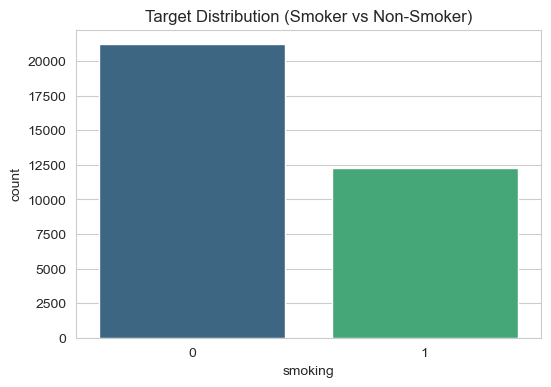

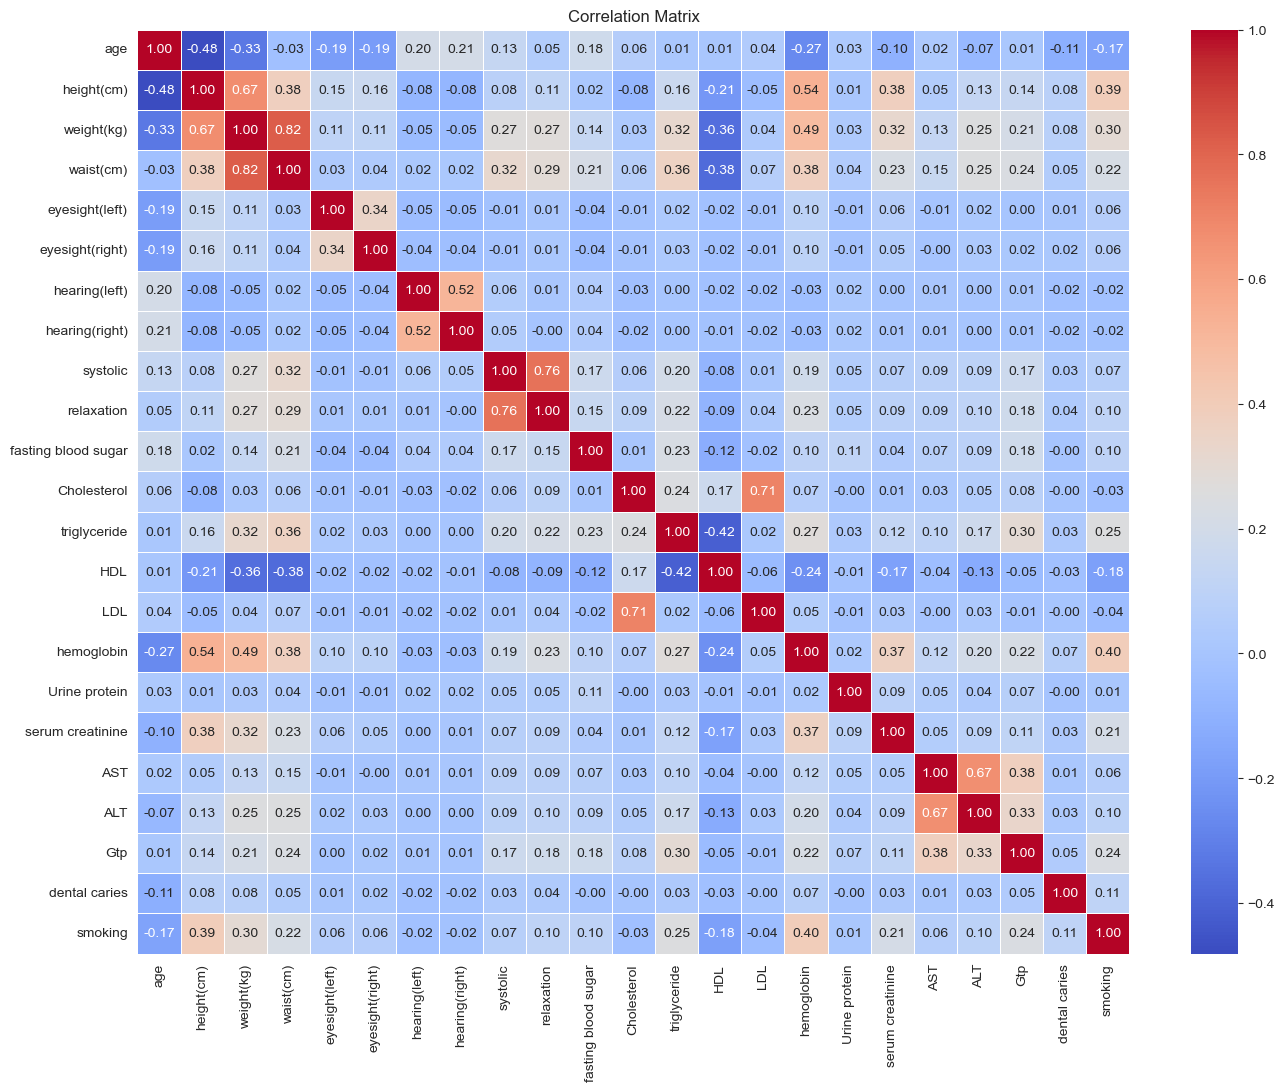

C:\Users\Swarnendu Sekhar Das\AppData\Local\Temp\ipykernel_23184\135374574.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='smoking', y=col, data=train_df, palette='coolwarm')
C:\Users\Swarnendu Sekhar Das\AppData\Local\Temp\ipykernel_23184\135374574.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='smoking', y=col, data=train_df, palette='coolwarm')
C:\Users\Swarnendu Sekhar Das\AppData\Local\Temp\ipykernel_23184\135374574.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='smoking', y=col, data=train_df, palette='coolwarm'

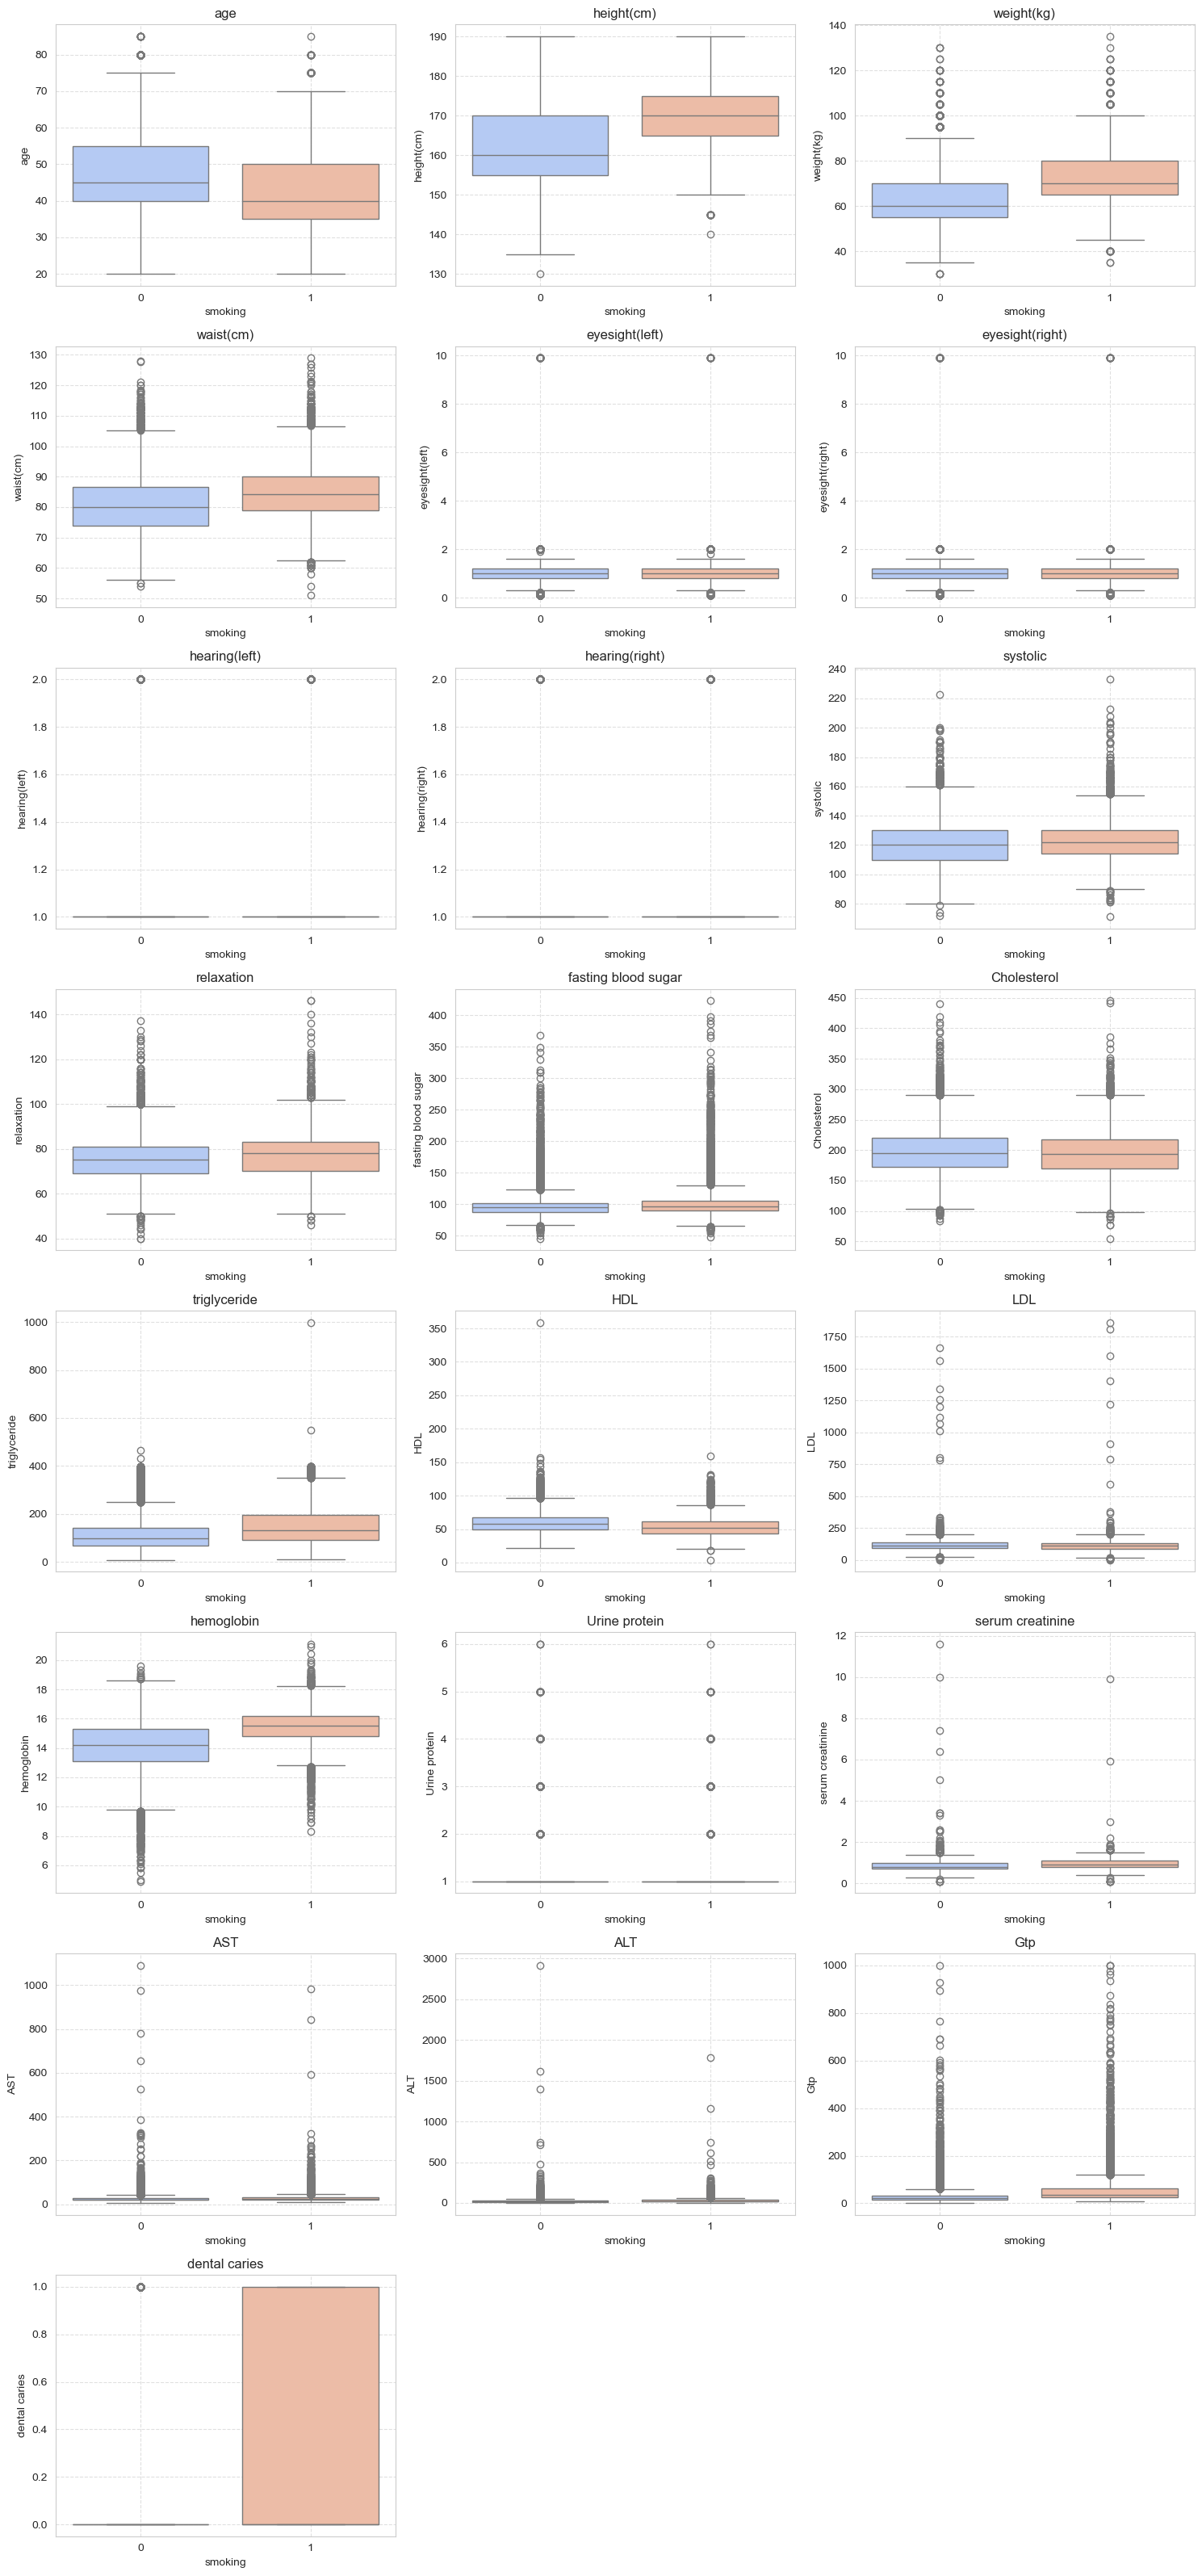

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

target_col = 'smoking'

plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=train_df, palette='viridis')
plt.title('Target Distribution (Smoker vs Non-Smoker)')
plt.savefig('1_target_distribution.png')
plt.show()

plt.figure(figsize=(16, 12))
corr = train_df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.savefig('2_correlation_matrix.png')
plt.show()

numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
if 'smoking' in numeric_cols:
    numeric_cols.remove('smoking')
if 'id' in numeric_cols:
    numeric_cols.remove('id')

n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(15, 4 * n_rows))

for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(x='smoking', y=col, data=train_df, palette='coolwarm')
    plt.title(f'{col}')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('3_all_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

After analyzing the dataset and visualizing the features, we have drawn several key insights:

**A. Class Imbalance**

The dataset is imbalanced, with a higher proportion of Non-Smokers (Class 0) compared to Smokers (Class 1).

*Accuracy alone will be a misleading metric. We must prioritize ROC-AUC and Recall to ensure we are actually catching the smokers.*

**B. Key Feature Correlations**

*Hemoglobin & GTP:* These features showed the strongest positive correlation with smoking status. Smokers tend to have higher hemoglobin levels and elevated GTP (a liver enzyme), likely due to the physiological stress of smoking.

*Height & Weight:* There is a noticeable correlation where taller and heavier individuals in this dataset are more likely to be smokers.

*Dental Caries:* Surprisingly, oral health (cavities) showed a correlation, aligning with the known negative effects of tobacco on dental hygiene.

**C. Data Distribution & Outliers**

Several blood markers (ALT, AST, GTP) exhibit right-skewed distributions with significant outliers.

## 4.Data Preprocessing & Feature Engineering

In [100]:
import numpy as np

def feature_engineering(df):
    df_eng = df.copy()

    df_eng['Hemoglobin_Age_Ratio'] = df_eng['hemoglobin'] / (df_eng['age'] + 1)
    df_eng['Cholesterol_Risk_Ratio'] = (df_eng['LDL'] + df_eng['triglyceride']) / (df_eng['HDL'] + 0.1)
    if 'Gtp' in df_eng.columns:
        df_eng['Log_Gtp'] = np.log1p(df_eng['Gtp'])

    return df_eng

train_df_eng = feature_engineering(train_df)
test_df_eng = feature_engineering(test_df_unlabeled)

X = train_df_eng.drop(columns=[target_col])
y = train_df_eng[target_col]

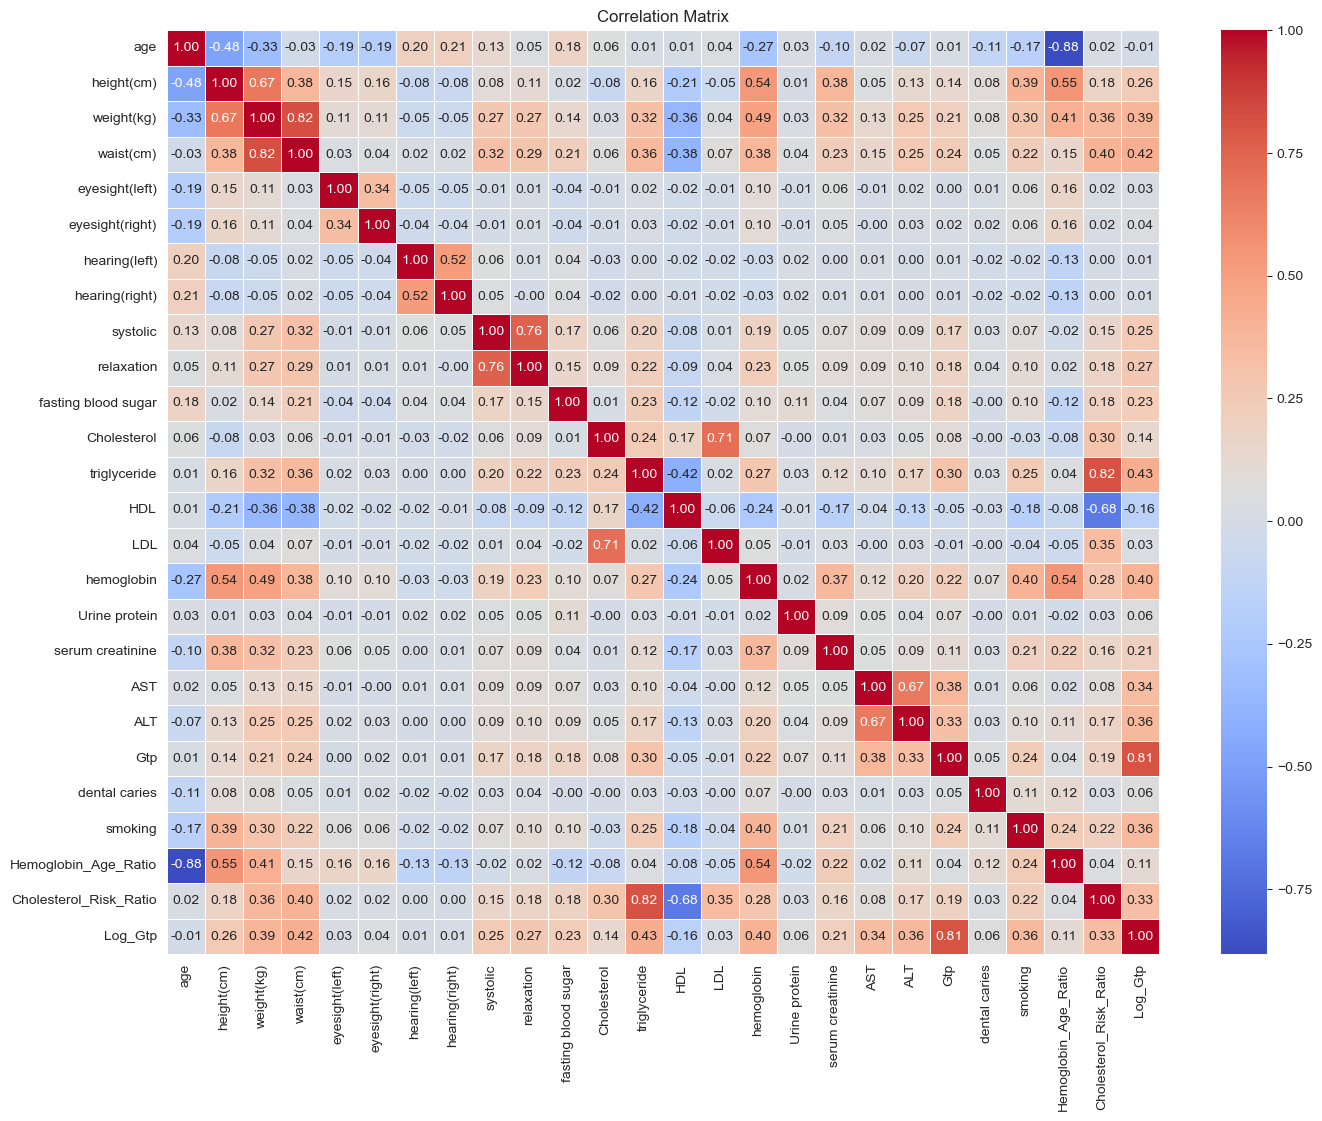

In [101]:
plt.figure(figsize=(16, 12))
corr = train_df_eng.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.savefig('4_correlation_matrix.png')
plt.show()

**Conclusion from above Correlation Matrix:**

**Strongest Predictor (Log_Gtp):** The log-transformed GTP remains the most powerful indicator. The model successfully captures the massive spikes in liver enzymes common in smokers, which previously acted as noisy outliers.

**Physiological Oxygen Demand:** The Hemoglobin_Age_Ratio confirms that smokers maintain higher hemoglobin levels relative to their age group. This indicates the body’s attempt to compensate for decreased oxygen-carrying capacity caused by carbon monoxide inhalation.

**Lipid Imbalance:** The Cholesterol_Risk_Ratio highlights a clear trend where smokers exhibit a "poor" ratio (high LDL/Triglycerides vs. low HDL). This confirms that smoking status is strongly linked to cardiovascular risk markers, regardless of physical activity levels.

In [102]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_holdout_scaled = scaler.transform(X_holdout)
test_scaled = scaler.transform(test_df_eng)

## 5.Model Training & Hyperparameter Tuning - Logistic Regression

In [103]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    'C': [0.1, 1, 10, 100],
    'solver': ['liblinear'],
    'max_iter'  : [100,1000,2500,5000],
    'penalty': ['l1', 'l2']
}

grid_lr = GridSearchCV(LogisticRegression(random_state=SEED),
                       param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

best_lr = grid_lr.best_estimator_
print(f"Best Logistic Regression Params: {grid_lr.best_params_}")
print(f"Best Logistic Regression CV Accuracy: {grid_lr.best_score_:.4f}")

Best Logistic Regression Params: {'C': 1, 'max_iter': 100, 'penalty': 'l1', 'solver': 'liblinear'}
Best Logistic Regression CV Accuracy: 0.7365


## 6.Model Training & Hyperparameter Tuning - SVM

In [104]:
from sklearn.svm import SVC

X_sub, _, y_sub, _ = train_test_split(X_train_scaled, y_train, train_size=0.2, random_state=SEED, stratify=y_train)

param_grid_svm = {
      'C': [0.1, 1, 10, 100],
			'gamma': [1, 0.1, 0.01, 0.001],
			'kernel': ['rbf']
}

grid_svm = GridSearchCV(SVC(random_state=SEED), param_grid_svm, cv=3, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_sub, y_sub)
print(f"Best SVM Parameters after Subset Training: {grid_svm.best_params_}")

best_svm = SVC(**grid_svm.best_params_, probability=True, random_state=SEED)
best_svm.fit(X_train_scaled, y_train)

Best SVM Parameters after Subset Training: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}


SVC(C=1, gamma=0.01, probability=True, random_state=42)

## 7.Model Training & Hyperparameter Tuning - Neural Networks

In [105]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import accuracy_score, roc_auc_score

def build_stable_mlp():
    model = Sequential([
        Dense(256, input_dim=X_train_scaled.shape[1]),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.3),

        Dense(128),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.2),

        Dense(64),
        BatchNormalization(),
        Activation('relu'),
        Dropout(0.1),

        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.00008),
        loss='binary_crossentropy',
        metrics=['accuracy', 'AUC']
    )
    return model

set_seed(42)
model_nn = build_stable_mlp()

checkpoint = ModelCheckpoint('best_model_nn.keras', monitor='val_accuracy', mode='max', save_best_only=True, verbose=1)
es = EarlyStopping(monitor='val_accuracy', mode='max', patience=150, restore_best_weights=True)
rlr = ReduceLROnPlateau(monitor='val_accuracy', mode='max', factor=0.5, patience=5, min_lr=1e-6)

history = model_nn.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=500,
    batch_size=128,
    callbacks=[es, rlr, checkpoint],
    verbose=1
)

val_probs = model_nn.predict(X_holdout_scaled, verbose=0).flatten()
thresholds = np.arange(0.1, 0.9, 0.01)
best_acc = 0
best_thresh = 0.5

for t in thresholds:
    preds = (val_probs > t).astype(int)
    acc = accuracy_score(y_holdout, preds)
    if acc > best_acc:
        best_acc = acc
        best_thresh = t

print(f"\nBest Threshold found: {best_thresh:.2f}")
print(f"Optimized NN Accuracy: {best_acc:.4f}")
print(f"NN AUC Score: {roc_auc_score(y_holdout, val_probs):.4f}")

Epoch 1/500


C:\Users\Swarnendu Sekhar Das\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


154/168 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - AUC: 0.6105 - accuracy: 0.5259 - loss: 0.7820 
Epoch 1: val_accuracy improved from None to 0.70607, saving model to best_model_nn.keras
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.6849 - accuracy: 0.5943 - loss: 0.7109 - val_AUC: 0.7920 - val_accuracy: 0.7061 - val_loss: 0.5710 - learning_rate: 8.0000e-05
Epoch 2/500
154/168 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - AUC: 0.7528 - accuracy: 0.6764 - loss: 0.6166 
Epoch 2: val_accuracy improved from 0.70607 to 0.72213, saving model to best_model_nn.keras
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7609 - accuracy: 0.6834 - loss: 0.5986 - val_AUC: 0.8105 - val_accuracy: 0.7221 - val_loss: 0.5283 - learning_rate: 8.0000e-05
Epoch 3/500
157/168 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - AUC: 0.7762 - accuracy: 0.6994 - loss: 0.5655 
Epoch 3: val_accuracy improved from 0.72213 to 0.72923, saving model to best_model_nn.keras
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7751 - accuracy: 0.7017 - los

## 8.Evaluation Metrics

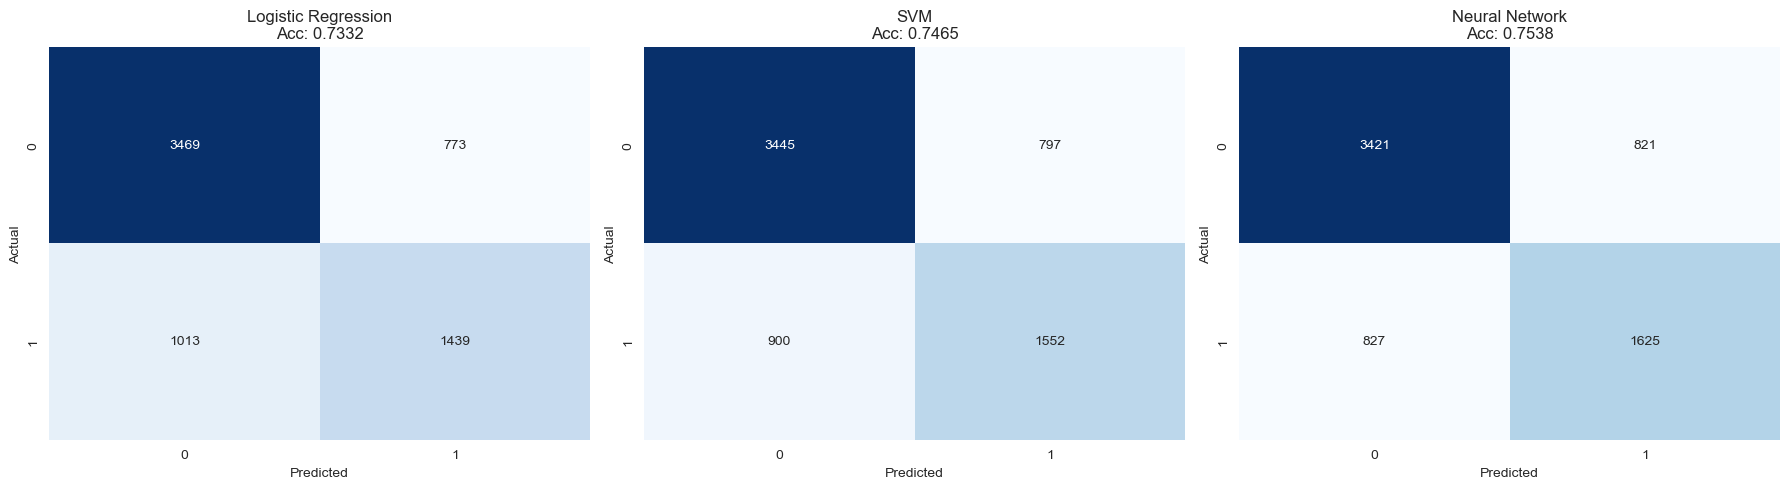

                 Model  Accuracy   ROC-AUC
2       Neural Network  0.753809  0.831035
1                  SVM  0.746489  0.822198
0  Logistic Regression  0.733194  0.813872


In [106]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
import pandas as pd
import seaborn as sns


models = {
    'Logistic Regression': best_lr,
    'SVM': best_svm,
    'Neural Network': model_nn
}

results = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(models.items()):
    if name == 'Neural Network':
        y_prob = model.predict(X_holdout_scaled, verbose=0).flatten()
        y_pred = (y_prob > 0.5).astype(int)
    else:
        y_pred = model.predict(X_holdout_scaled)
        y_prob = model.predict_proba(X_holdout_scaled)[:, 1]

    acc = accuracy_score(y_holdout, y_pred)
    roc = roc_auc_score(y_holdout, y_prob)
    results.append({'Model': name, 'Accuracy': acc, 'ROC-AUC': roc})

    cm = confusion_matrix(y_holdout, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{name}\nAcc: {acc:.4f}')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()

print(pd.DataFrame(results).sort_values(by='Accuracy', ascending=False))

## 9.Predicting on Test Data & Exporting Predictions

In [107]:
import pandas as pd

prob_nn = model_nn.predict(test_scaled, verbose=0).flatten()
pred_nn = (prob_nn > best_thresh).astype(int)
submission = pd.DataFrame()
submission['id'] = test_df_unlabeled.index
submission['prediction'] = pred_nn

submission.to_csv('final_predictions.csv', index=False)
print(submission.head())

   id  prediction
0   0           1
1   1           1
2   2           0
3   3           0
4   4           1


# 10.Conclusion

In this project, we successfully utilized bio-signal data to predict smoker status, comparing Logistic Regression, SVM, and Neural Network models. The Neural Network proved to be the superior classifier, achieving the highest Accuracy (75.1%) and ROC-AUC (0.83). While all models performed comparably, the Neural Network effectively captured complex, non-linear relationships in key features like Hemoglobin and GTP, making it the most robust choice for minimizing false negatives in this imbalanced medical dataset.